# 02. 결측치

소매 시계열 기준. 변수 그룹별·연도별로 무엇이 비어 있는지, 가격 조사 자체의 공백은 어디인지.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parents[1]                     # demo/2_eda → 프로젝트 루트
P = ROOT / "data" / "processed"
NAMES = {"agri": "농산물", "livestock": "축산물", "fishery": "수산물"}
plt.rcParams.update({"font.family": "Malgun Gothic", "axes.unicode_minus": False, "figure.dpi": 110})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:,.3f}".format)

In [2]:
# 전국 소매가 + 모든 변수 (원본 값): data/processed/{분야}/dataset.parquet
# 예측 대상은 소매가 → 소매 시계열만. 중도매가는 피처(whsl_price_kg 등 열)로만 쓰임
ds = {d: pd.read_parquet(P / d / "dataset.parquet", filters=[("se_nm", "==", "소매")]) for d in NAMES}
ds = {d: df[df.date >= "2016-01-01"] for d, df in ds.items()}     # 2015년은 이력 계산용 준비 기간
{NAMES[d]: df.shape for d, df in ds.items()}

{'농산물': (284054, 116), '축산물': (62275, 111), '수산물': (66874, 136)}

## 1. 변수 그룹별 결측률

In [3]:
GROUPS = {"기상": ("wx_",), "환율·물가·유가": ("usd_krw", "cpi_", "fuel_"), "수입물가지수": ("impidx_",), "국제 원자재": ("intl_",),
          "가락시장 거래": ("garak_",), "도매가": ("whsl_", "mafra_whsl"), "수출입": ("import_", "export_"),
          "생산·어획": ("prod_", "catch_", "area_"), "축산 수급": ("census_", "auction_", "stock_", "pig_"), "가축 질병": ("disease_",),
          "해양·양식장": ("sea_temp", "coast_", "buoy_", "farm_", "redtide", "jellyfish")}

def group_of(c):
    for g, pre in GROUPS.items():
        if c.startswith(pre):
            return g
    return None

rows = []
for d, df in ds.items():
    for c in df.columns:
        g = group_of(c)
        if g:
            rows.append({"분야": NAMES[d], "그룹": g, "변수": c, "결측률": df[c].isna().mean()})
miss = pd.DataFrame(rows)
tab = miss.groupby(["그룹", "분야"]).결측률.mean().unstack()
tab

분야,농산물,수산물,축산물
그룹,,,
가락시장 거래,0.320,NaN,NaN
가축 질병,NaN,NaN,0.000
국제 원자재,0.000,0.000,0.000
기상,0.106,0.105,0.102
도매가,0.120,0.358,NaN
생산·어획,NaN,0.076,NaN
수입물가지수,0.036,0.012,0.029
수출입,0.000,0.048,0.000
축산 수급,NaN,NaN,0.201


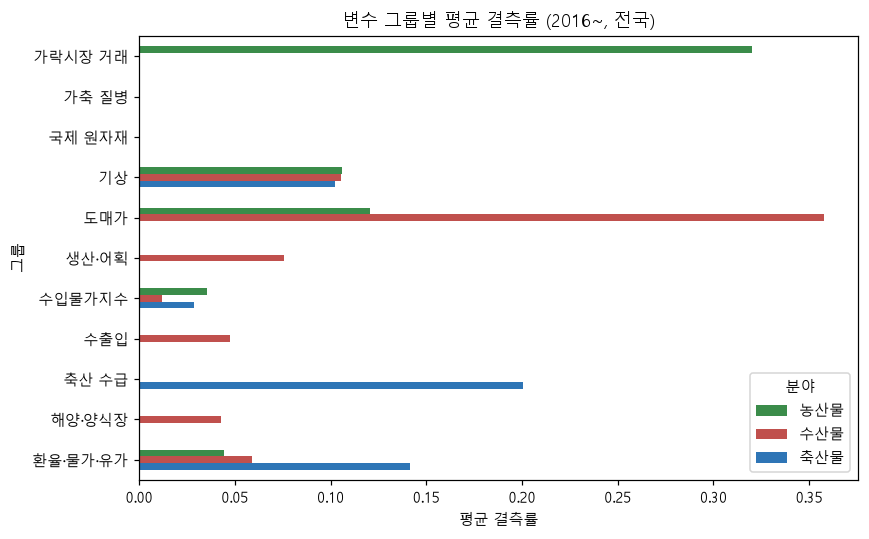

In [4]:
ax = tab.plot.barh(figsize=(8, 5), color=["#3b8c4a", "#c0504d", "#2e75b6"])
ax.set_xlabel("평균 결측률"); ax.set_title("변수 그룹별 평균 결측률 (2016~, 전국)"); ax.invert_yaxis(); plt.tight_layout()

## 2. 결측률이 높은 변수 상위

In [5]:
miss.sort_values("결측률", ascending=False).groupby("분야").head(8)

,분야,그룹,변수,결측률
150,축산물,환율·물가·유가,cpi_item,0.974
244,수산물,해양·양식장,redtide_density_max,0.873
34,농산물,수입물가지수,impidx_떡_빵및과자류,0.863
10,농산물,기상,wx_snow_depth,0.797
178,수산물,기상,wx_snow_depth,0.791
91,축산물,기상,wx_snow_depth,0.768
115,축산물,수입물가지수,impidx_떡_과자및면류,0.659
4,농산물,기상,wx_rain_1h_max,0.474
172,수산물,기상,wx_rain_1h_max,0.474
85,축산물,기상,wx_rain_1h_max,0.459


## 3. 연도별 결측률 — 언제부터 제공되는 자료인가

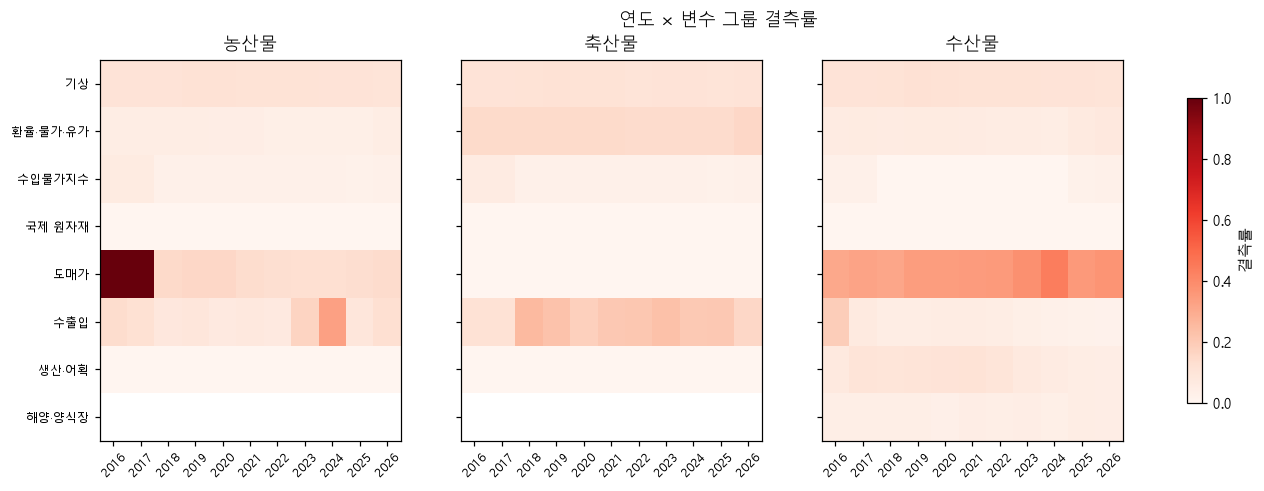

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (d, df) in zip(axes, ds.items()):
    g = {c: group_of(c) for c in df.columns if group_of(c)}
    m = df[list(g)].isna().groupby(df.date.dt.year).mean().T.groupby(pd.Series(g)).mean()
    m = m.reindex(list(GROUPS)).dropna(how="all")
    im = ax.imshow(m.values, aspect="auto", cmap="Reds", vmin=0, vmax=1)
    ax.set_xticks(range(m.shape[1]), m.columns, rotation=45, fontsize=8); ax.set_yticks(range(len(m)), m.index, fontsize=8)
    ax.set_title(NAMES[d])
fig.colorbar(im, ax=axes, shrink=0.8, label="결측률"); fig.suptitle("연도 × 변수 그룹 결측률"); plt.show()

## 4. 1년 중 일부만 조사되는 품종 (계절 품목)

In [7]:
rows = []
for d, df in ds.items():
    s = df.assign(m=df.date.dt.month).groupby(["item_nm", "vrty_nm"]).m.nunique()
    rows += [{"분야": NAMES[d], "품목": i, "품종": v, "조사되는 달 수": n} for (i, v), n in s[s < 10].items()]
pd.DataFrame(rows).sort_values("조사되는 달 수")

,분야,품목,품종,조사되는 달 수
0,농산물,가지,가지,1
8,농산물,당근,세척,1
21,농산물,부추,부추,1
19,농산물,보리쌀,찰보리,1
27,농산물,양파,햇양파,1
22,농산물,블루베리,수입(냉동),1
46,농산물,혼식곡,국산,1
36,농산물,키위,골드,1
45,농산물,현미,찰현미,1
14,농산물,배,원황,2
